# PG-LIF — Phase P3b (revision R1): Plateau-Gated e-prop on SHD (Regime B)
**Produces:** manuscript Section 7.2 (Table 2).

**What changed in this revision run, and why**
1. **Two strictly neuron-local gate normalizations (Reviewer 2, point 5).** The published `plateau-gated` rule divides the gate by its mean over the batch *and over all neurons* of the layer at every time step, a cross-neuron reduction that is not neuron-local. The reviewer named two local alternatives; both are evaluated here exactly as named:
   - `plateau-gated-runavg` — each neuron divides its own gate by its own running (exponential) average of that gate; no information from other neurons is used.
   - `plateau-gated-fixed` — each layer's gate is divided by one fixed scale, calibrated once before training on 10 training batches (no weight updates) and then frozen.
2. **Log-only numerical-stability instrumentation (Reviewer 2, point 4).** Every step records whether any raw (pre-clamp) e-prop update was non-finite. This is **measurement only**: no step is discarded, so the published three rules run under exactly their published protocol. The final weights are also checked for finiteness.
3. **Measured training time per epoch** and the mean applied gate per epoch (so effective learning-rate scale can be compared across rules).
4. **All five rules re-run in one fresh folder under one code version** (no reuse of older results), so every comparison is like-for-like.

**Pre-specified reading (fixed before running).** Primary: does replacing the cross-neuron normalization with a neuron-local one change accuracy relative to the published `plateau-gated` rule (paired over seeds; mean difference with 95% CI)? If both local variants are within noise of `plateau-gated`, the manuscript states that the Regime B result does not depend on the non-local normalization; if a local variant is worse (or better), that is reported as measured. With n = 5 seeds, results are reported as effect sizes with CIs, not as decisive tests.

**Runtime:** 5 rules × 5 seeds × 20 epochs, about 30–40 min per (rule, seed) on a T4; resumable per (rule, seed). Results to `My Drive/PG_LIF/P3_results/gated_eprop_R1/`.

In [1]:
import os, json, time, math
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/My Drive'
    if not os.path.isdir(ROOT): ROOT = '/content/drive/MyDrive'
    BASE = os.path.join(ROOT, 'PG_LIF')
except Exception:
    BASE = './PG_LIF'
DATA = os.path.join(BASE, 'data', 'SHD')
P3_ROOT = os.path.join(BASE, 'P3_results')
OUT = os.path.join(P3_ROOT, 'gated_eprop_R1')   # revision run: fresh, fixed-name folder; never mixed with older runs
os.makedirs(OUT, exist_ok=True)
T_BINS, MAX_TIME, N_IN, N_OUT, HIDDEN, BATCH, LR = 100, 1.4, 700, 20, 128, 64, 1e-3
EPOCHS = 20
SEEDS = [0, 1, 2, 3, 4]
RULES = ['eprop', 'plateau-gated', 'permuted-gated', 'plateau-gated-runavg', 'plateau-gated-fixed']
# Neuron-local normalization settings (fixed before running; reported in the manuscript's hyperparameter table)
CALIB_BATCHES = 10                     # batches used to calibrate the fixed scale and to initialize the running average
RUNAVG_TAU_STEPS = 10 * T_BINS         # running-average time constant: ~10 samples' worth of time steps
GATE_EPS = 0.05                        # floor on the normalizer, so a rarely-gated neuron cannot get an unbounded gate
print('Results folder:', OUT)

Mounted at /content/drive
Results folder: /content/drive/My Drive/PG_LIF/P3_results/gated_eprop_R1


In [2]:
import numpy as np, h5py, torch, torch.nn as nn
def load_split(fname):
    with h5py.File(os.path.join(DATA, fname), 'r') as f:
        return ([np.array(t) for t in f['spikes']['times']],
                [np.array(u) for u in f['spikes']['units']],
                np.array(f['labels'], dtype=np.int64))
TR = load_split('shd_train.h5'); TE = load_split('shd_test.h5')
def batches(split, batch_size, shuffle, device='cpu'):
    times, units, labels = split
    idx = np.random.permutation(len(labels)) if shuffle else np.arange(len(labels))
    for b0 in range(0, len(idx), batch_size):
        sel = idx[b0:b0+batch_size]
        x = torch.zeros(len(sel), T_BINS, N_IN)
        for i, j in enumerate(sel):
            tt = times[j]; uu = units[j]; keep = tt < MAX_TIME
            tb = np.clip((tt[keep] / MAX_TIME * T_BINS).astype(int), 0, T_BINS-1)
            x[i, tb, uu[keep]] = 1.0
        yield x.to(device), torch.as_tensor(labels[sel]).to(device)
print('train', len(TR[2]), '| test', len(TE[2]))
# revision R1: the published metric scores only the first 1024 test samples; check whether they cover all classes evenly
_c_sub = np.bincount(TE[2][:1024], minlength=N_OUT); _c_all = np.bincount(TE[2], minlength=N_OUT)
print('test samples per class, first 1024:', _c_sub.tolist())
print('test samples per class, all       :', _c_all.tolist())
print(f'classes missing from the first 1024: {int((_c_sub == 0).sum())}; max/min class share ratio in subset: '
      f'{(_c_sub.max() / max(_c_sub.min(), 1)):.2f} (full set: {(_c_all.max() / max(_c_all.min(), 1)):.2f})')

train 8156 | test 2264
test samples per class, first 1024: [48, 48, 50, 51, 44, 51, 47, 49, 49, 45, 57, 58, 57, 54, 47, 43, 49, 62, 51, 64]
test samples per class, all       : [103, 108, 105, 102, 116, 110, 109, 109, 114, 103, 122, 121, 121, 120, 115, 112, 118, 121, 123, 112]
classes missing from the first 1024: 0; max/min class share ratio in subset: 1.49 (full set: 1.21)


## Forward-only PG-LIF network with e-prop traces
Identical dynamics and update to the published run. Additions: (i) the two neuron-local gate normalizations, (ii) log-only counting of non-finite raw updates, (iii) gate statistics. Nothing in the `eprop`, `plateau-gated` or `permuted-gated` code path changes its arithmetic.

In [3]:
def decay(tau): return math.exp(-1.0 / tau)
AM, AD, AP, AO = decay(20), decay(20), decay(50), decay(20)
TH, TH_D, TREF_P, PMAX = 1.0, 1.0, 10, 2.0
PSI_SCALE = 0.3
RA_BETA = math.exp(-1.0 / RUNAVG_TAU_STEPS)

class EpropNet:
    def __init__(self, seed, device):
        torch.manual_seed(seed)
        self.dev = device
        self.w_in = (torch.randn(HIDDEN, N_IN, device=device) / math.sqrt(N_IN)).requires_grad_(False)
        self.w_rec = torch.linalg.qr(torch.randn(HIDDEN, HIDDEN, device=device))[0]
        self.w_out = torch.zeros(N_OUT, HIDDEN, device=device)
        self.b_out = torch.zeros(N_OUT, device=device)
        self.params = {'w_in': self.w_in, 'w_rec': self.w_rec, 'w_out': self.w_out, 'b_out': self.b_out}
        self.adam_m = {k: torch.zeros_like(v) for k, v in self.params.items()}
        self.adam_v = {k: torch.zeros_like(v) for k, v in self.params.items()}
        self.adam_t = 0
        # revision R1: log-only stability counters and gate statistics
        self.total_steps = 0
        self.nonfinite_steps = 0                       # steps whose RAW (pre-clamp) update had any non-finite entry
        # gate statistics are accumulated ON THE DEVICE and read once per epoch, so logging adds no per-step
        # host synchronization to the gated rules (otherwise their measured training time would be inflated)
        self.gate_sum = torch.zeros((), device=device); self.gate_n = 0
        self.gate_active_sum = torch.zeros((), device=device)
        # revision R1: neuron-local normalizers (set by calibrate())
        self.fixed_scale = None                        # scalar per layer (one hidden layer here)
        self.g_ema = None                              # (HIDDEN,) per-neuron running average

    def _raw_gate(self, p):
        return torch.clamp(p / PMAX, max=1.0)

    def _normalize(self, graw, rule):
        if rule in ('plateau-gated', 'permuted-gated'):
            return graw / graw.mean().clamp(min=1e-4)              # published: cross-neuron, per-step unit mean
        if rule == 'plateau-gated-fixed':
            return graw / max(self.fixed_scale, GATE_EPS)          # one frozen, pre-calibrated scale
        if rule == 'plateau-gated-runavg':
            # per-neuron running average of that neuron's own gate (averaged over the samples of the batch,
            # which is equivalent in expectation to presenting them one after another); no other neuron is used
            self.g_ema = RA_BETA * self.g_ema + (1 - RA_BETA) * graw.mean(0)
            return graw / self.g_ema.clamp(min=GATE_EPS).unsqueeze(0)
        raise ValueError(rule)

    def forward_train(self, x, y, rule, update=True, calib=None):
        B, T, _ = x.shape; dev = self.dev
        z = lambda *s: torch.zeros(*s, device=dev)
        vs, vd, p, rp = z(B, HIDDEN), z(B, HIDDEN), z(B, HIDDEN), z(B, HIDDEN)
        s = z(B, HIDDEN); vo = z(B, N_OUT); out_run = z(B, N_OUT)
        xtr_in = z(B, N_IN); xtr_rec = z(B, HIDDEN)
        el_in = z(B, HIDDEN, N_IN); el_rec = z(B, HIDDEN, HIDDEN)
        otr = z(B, HIDDEN)
        g_in = z(HIDDEN, N_IN); g_rec = z(HIDDEN, HIDDEN); g_out = z(N_OUT, HIDDEN); g_b = z(N_OUT)
        y1 = torch.nn.functional.one_hot(y, N_OUT).float()
        nspk = 0.0
        for t in range(T):
            xt = x[:, t]
            iff = xt @ self.w_in.T; irec = s @ self.w_rec.T
            vd = AD * vd + iff
            ed = ((vd >= TH_D) & (rp == 0)).float()
            rp = torch.clamp(rp - 1, min=0) + ed * TREF_P
            p = AP * p + ed
            if calib is not None:                       # calibration pass: record raw-gate statistics only
                g = self._raw_gate(p); calib['sum'] += g.sum(0); calib['n'] += B
            vs = AM * vs + iff + irec
            s_new = (vs >= TH).float()
            psi = PSI_SCALE * torch.clamp(1.0 - (vs - TH).abs(), min=0.0)
            vs = vs - s_new * TH
            nspk += s_new.sum().item()
            xtr_in = AM * xtr_in + xt
            xtr_rec_prev = xtr_rec
            xtr_rec = AM * xtr_rec + s
            if not update:
                s = s_new; continue
            el_in = AO * el_in + psi.unsqueeze(2) * xtr_in.unsqueeze(1)
            el_rec = AO * el_rec + psi.unsqueeze(2) * xtr_rec_prev.unsqueeze(1)
            s = s_new
            otr = AO * otr + s
            vo = AO * vo + s @ self.w_out.T + self.b_out
            out_run = out_run + vo
            err = torch.softmax(out_run / (t + 1), dim=1) - y1
            L = err @ self.w_out
            if rule == 'eprop':
                gate = torch.ones(B, HIDDEN, device=dev)
            else:
                graw = self._raw_gate(p)
                if rule == 'permuted-gated':
                    graw = graw[:, torch.randperm(HIDDEN, device=dev)]
                gate = self._normalize(graw, rule)
                self.gate_sum += gate.mean().detach(); self.gate_n += 1
                self.gate_active_sum += (gate > 0).float().mean()
            LG = L * gate
            g_in += torch.einsum('bh,bhj->hj', LG, el_in) / B
            g_rec += torch.einsum('bh,bhj->hj', LG, el_rec) / B
            g_out += err.T @ otr / B
            g_b += err.mean(0)
        if not update:
            return nspk / B
        grads = {'w_in': g_in / T, 'w_rec': g_rec / T, 'w_out': g_out / T, 'b_out': g_b / T}
        # revision R1: LOG-ONLY finiteness check on the raw update, before the clamp (a clamp would hide it).
        # Nothing is skipped: the published protocol is reproduced exactly.
        self.total_steps += 1
        if any(not torch.isfinite(gr).all() for gr in grads.values()):
            self.nonfinite_steps += 1
        self.adam_t += 1
        for k, gr in grads.items():
            gr = torch.clamp(gr, -1.0, 1.0)
            self.adam_m[k] = 0.9 * self.adam_m[k] + 0.1 * gr
            self.adam_v[k] = 0.999 * self.adam_v[k] + 0.001 * gr * gr
            mh = self.adam_m[k] / (1 - 0.9 ** self.adam_t)
            vh = self.adam_v[k] / (1 - 0.999 ** self.adam_t)
            self.params[k] -= LR * mh / (vh.sqrt() + 1e-8)
        return nspk / B

    def calibrate(self, batch_iter, n_batches):
        """Revision R1: measure the raw gate's mean over n_batches with NO weight update, then freeze it.
        Sets both the fixed layer scale and the per-neuron initial value of the running average."""
        calib = {'sum': torch.zeros(HIDDEN, device=self.dev), 'n': 0}
        for i, (x, y) in enumerate(batch_iter):
            if i >= n_batches: break
            self.forward_train(x, y, 'eprop', update=False, calib=calib)
        per_neuron = calib['sum'] / max(calib['n'], 1)
        self.fixed_scale = float(per_neuron.mean())
        self.g_ema = per_neuron.clone()
        return self.fixed_scale, per_neuron

    def params_finite(self):
        return all(bool(torch.isfinite(v).all()) for v in self.params.values())

    def forward_eval(self, x):
        B, T, _ = x.shape; dev = self.dev
        z = lambda *sh: torch.zeros(*sh, device=dev)
        vs = z(B, HIDDEN); s = z(B, HIDDEN); vo = z(B, N_OUT); out = z(B, N_OUT)
        for t in range(T):
            iff = x[:, t] @ self.w_in.T; irec = s @ self.w_rec.T
            vs = AM * vs + iff + irec
            s = (vs >= TH).float(); vs = vs - s * TH
            vo = AO * vo + s @ self.w_out.T + self.b_out
            out = out + vo
        return out

def accuracy(net, split, device, limit=1024):
    correct = tot = 0
    for x, y in batches(split, 256, shuffle=False, device=device):
        out = net.forward_eval(x)
        correct += (out.argmax(1) == y).sum().item(); tot += len(y)
        if tot >= limit: break
    return correct / tot

## Training runs (resumable per rule and seed)

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cpu': print('WARNING: no GPU - slow.')
def run_rule(rule, seed):
    res_file = os.path.join(OUT, f'{rule}_s{seed}.json')
    if os.path.exists(res_file):                       # resume within THIS revision folder only
        print('[skip]', rule, seed, '(already finished in this folder)'); return json.load(open(res_file))
    np.random.seed(seed)
    net = EpropNet(seed, device)
    calib_info = None
    if rule in ('plateau-gated-fixed', 'plateau-gated-runavg'):
        rng_state = np.random.get_state()
        np.random.seed(10_000 + seed)                  # calibration batches drawn from the TRAINING set only
        scale, per_neuron = net.calibrate(batches(TR, BATCH, shuffle=True, device=device), CALIB_BATCHES)
        np.random.set_state(rng_state)                 # training batch order identical to the other rules
        calib_info = {'fixed_scale': scale, 'per_neuron_min': float(per_neuron.min()),
                      'per_neuron_max': float(per_neuron.max()),
                      'frac_neurons_below_eps': float((per_neuron < GATE_EPS).float().mean())}
        print(f'[calib] {rule} s{seed}: layer scale {scale:.4f}; per-neuron range '
              f"[{calib_info['per_neuron_min']:.4f}, {calib_info['per_neuron_max']:.4f}]")
    hist = []
    for ep in range(EPOCHS):
        t0 = time.time(); g0, n0, a0 = float(net.gate_sum), net.gate_n, float(net.gate_active_sum)
        for x, y in batches(TR, BATCH, shuffle=True, device=device):
            net.forward_train(x, y, rule)
        if device == 'cuda': torch.cuda.synchronize()
        t_train = time.time() - t0
        dn = net.gate_n - n0
        hist.append({'epoch': ep, 'train_acc': accuracy(net, TR, device),
                     'test_acc': accuracy(net, TE, device),                       # published metric: first 1024 test samples
                     'test_acc_full': accuracy(net, TE, device, limit=10**9),     # full SHD test set (2,264 samples)
                     'train_seconds': t_train,
                     'mean_gate': (float(net.gate_sum) - g0) / dn if dn else 1.0,
                     'frac_gate_active': (float(net.gate_active_sum) - a0) / dn if dn else 1.0})
        print(f"{rule:22s} s{seed} ep{ep:02d} train {hist[-1]['train_acc']:.3f} "
              f"test {hist[-1]['test_acc']:.3f} gate {hist[-1]['mean_gate']:.3f} {t_train:.0f}s "
              f"nonfinite-so-far {net.nonfinite_steps}")
    res = {'rule': rule, 'seed': seed, 'history': hist,
           'best_test': max(h['test_acc'] for h in hist),
           'best_test_full': max(h['test_acc_full'] for h in hist),
           'total_steps': net.total_steps, 'nonfinite_steps': net.nonfinite_steps,
           'nonfinite_rate': net.nonfinite_steps / net.total_steps if net.total_steps else 0.0,
           'final_params_finite': net.params_finite(),
           'mean_train_seconds_per_epoch': float(np.mean([h['train_seconds'] for h in hist])),
           'gpu': torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu',
           'calibration': calib_info,
           'settings': {'CALIB_BATCHES': CALIB_BATCHES, 'RUNAVG_TAU_STEPS': RUNAVG_TAU_STEPS, 'GATE_EPS': GATE_EPS}}
    json.dump(res, open(res_file, 'w'), indent=2)
    return res

# execution order: the two new neuron-local rules first (they answer Reviewer 2, point 5), then the
# re-runs of the three published rules (reproducibility check and log-only stability counts)
RUN_ORDER = ['plateau-gated-runavg', 'plateau-gated-fixed', 'eprop', 'plateau-gated', 'permuted-gated']
assert sorted(RUN_ORDER) == sorted(RULES)
RES = [run_rule(r, sd) for r in RUN_ORDER for sd in SEEDS]

[calib] plateau-gated-runavg s0: layer scale 0.3499; per-neuron range [0.0000, 0.8401]
plateau-gated-runavg   s0 ep00 train 0.377 test 0.429 gate 0.690 23s nonfinite-so-far 0
plateau-gated-runavg   s0 ep01 train 0.525 test 0.549 gate 0.633 23s nonfinite-so-far 0
plateau-gated-runavg   s0 ep02 train 0.617 test 0.582 gate 0.617 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep03 train 0.653 test 0.613 gate 0.626 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep04 train 0.691 test 0.624 gate 0.625 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep05 train 0.730 test 0.574 gate 0.624 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep06 train 0.695 test 0.567 gate 0.626 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep07 train 0.747 test 0.620 gate 0.622 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep08 train 0.769 test 0.619 gate 0.611 23s nonfinite-so-far 0
plateau-gated-runavg   s0 ep09 train 0.814 test 0.636 gate 0.610 22s nonfinite-so-far 0
plateau-gated-runavg   s0 ep10 tr

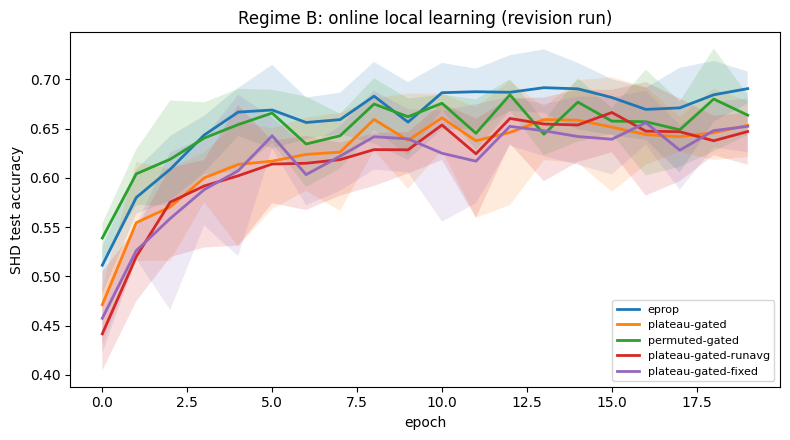

Accuracy columns: "subset" = first 1024 test samples (the published metric); "full" = all 2,264 test samples.

rule                      best test (%)   non-finite steps  final params finite  s/epoch  mean gate
eprop                        71.9 ± 0.9          0 / 12800                   True       20      1.000   full test set: 72.7 ± 0.8
plateau-gated                68.9 ± 1.3          0 / 12800                   True       22      1.000   full test set: 70.1 ± 1.0
permuted-gated               70.6 ± 1.5          0 / 12800                   True       23      1.000   full test set: 71.2 ± 1.0
plateau-gated-runavg         68.3 ± 1.0          0 / 12800                   True       22      0.606   full test set: 68.8 ± 1.0
plateau-gated-fixed          67.8 ± 1.3          0 / 12800                   True       21      0.830   full test set: 68.2 ± 1.3

Pre-specified comparisons (paired over seeds; mean difference in pp with 95% t-CI; n = 5, low power):
plateau-gated-runavg   - plateau-gat

In [5]:
import matplotlib.pyplot as plt
from scipy import stats
plt.figure(figsize=(8, 4.5))
for r in RULES:
    hs = [x for x in RES if x['rule'] == r]
    curves = np.array([[h['test_acc'] for h in x['history']] for x in hs])
    plt.plot(range(curves.shape[1]), curves.mean(0), lw=2, label=r)
    if curves.shape[0] > 1:
        plt.fill_between(range(curves.shape[1]), curves.min(0), curves.max(0), alpha=0.15)
plt.xlabel('epoch'); plt.ylabel('SHD test accuracy'); plt.legend(fontsize=8)
plt.title('Regime B: online local learning (revision run)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_p3b_R1.png'), dpi=300); plt.show()

by = {r: {x['seed']: x for x in RES if x['rule'] == r} for r in RULES}
print('Accuracy columns: "subset" = first 1024 test samples (the published metric); "full" = all 2,264 test samples.')
print(f"\n{'rule':22s} {'best test (%)':>16s} {'non-finite steps':>18s} {'final params finite':>20s} {'s/epoch':>8s} {'mean gate':>10s}")
for r in RULES:
    xs = list(by[r].values()); bt = [100 * x['best_test'] for x in xs]
    nf = sum(x['nonfinite_steps'] for x in xs); ts = sum(x['total_steps'] for x in xs)
    fin = all(x['final_params_finite'] for x in xs)
    sec = np.mean([x['mean_train_seconds_per_epoch'] for x in xs])
    mg = np.mean([np.mean([h['mean_gate'] for h in x['history']]) for x in xs])
    bf = [100 * x['best_test_full'] for x in xs]
    print(f"{r:22s} {np.mean(bt):10.1f} ± {np.std(bt, ddof=0):.1f} {nf:>10d} / {ts:<7d} {str(fin):>20s} {sec:8.0f} {mg:10.3f}"
          f"   full test set: {np.mean(bf):.1f} ± {np.std(bf, ddof=0):.1f}")

def paired(a, b):
    common = sorted(set(by[a]) & set(by[b]))
    d = np.array([100 * (by[a][s]['best_test'] - by[b][s]['best_test']) for s in common])
    m = d.mean(); se = d.std(ddof=1) / np.sqrt(len(d)); tcrit = stats.t.ppf(0.975, len(d) - 1)
    return m, (m - tcrit * se, m + tcrit * se), int((d > 0).sum()), len(d)
print(f'\nPre-specified comparisons (paired over seeds; mean difference in pp with 95% t-CI; n = {len(SEEDS)}, low power):')
for a, b in [('plateau-gated-runavg', 'plateau-gated'), ('plateau-gated-fixed', 'plateau-gated'),
             ('plateau-gated', 'eprop'), ('plateau-gated', 'permuted-gated'),
             ('plateau-gated-runavg', 'eprop'), ('plateau-gated-fixed', 'eprop')]:
    m, ci, k, n = paired(a, b)
    print(f'{a:22s} - {b:16s}: {m:+.2f} pp  [{ci[0]:+.2f}, {ci[1]:+.2f}]  ({k}/{n} seeds positive)')
summary = {r: {'best_test_mean': float(np.mean([x['best_test'] for x in by[r].values()])),
               'best_test_std': float(np.std([x['best_test'] for x in by[r].values()])),
               'per_seed': {s: x['best_test'] for s, x in by[r].items()},
               'best_test_full_mean': float(np.mean([x['best_test_full'] for x in by[r].values()])),
               'best_test_full_std': float(np.std([x['best_test_full'] for x in by[r].values()])),
               'nonfinite_steps_per_seed': {s: x['nonfinite_steps'] for s, x in by[r].items()},
               'total_steps_per_seed': {s: x['total_steps'] for s, x in by[r].items()},
               'final_params_finite_per_seed': {s: x['final_params_finite'] for s, x in by[r].items()},
               'train_seconds_per_epoch_per_seed': {s: x['mean_train_seconds_per_epoch'] for s, x in by[r].items()}}
           for r in RULES}
json.dump(summary, open(os.path.join(OUT, 'summary_R1.json'), 'w'), indent=2)
print('\nSaved', os.path.join(OUT, 'summary_R1.json'), '(with the per-run JSONs); these are the source of the manuscript tables.')

### Notes
- Reproducibility check: the `eprop`, `plateau-gated` and `permuted-gated` rows should reproduce the published Table 2 (71.9 ± 0.9, 68.9 ± 1.3, 70.6 ± 1.5) within GPU non-determinism. Report any difference rather than silently replacing the published numbers.
- The non-finite counter is log-only; a count of zero means no step of the published protocol was affected, and `final_params_finite` confirms the trained weights are intact.
- The running-average rule's normalizer uses each neuron's own gate history only; averaging over the samples of a mini-batch is a simulation convenience equivalent in expectation to sequential presentation.